# Assignment 1: Convolutional Neural Networks (CNNs)


## Import Packages


In [1]:
# Import torch packages
import torch
import torchvision as torchv

# Packages that are nice to have
import numpy as np
import matplotlib.pyplot as plt
from torchsummary import summary
from pathlib import Path
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

## Get the Dataset


In [2]:
train_dataset = torchv.datasets.CIFAR10(
    root='./dataset/train',
    train=True,
    download=True,
    transform=torchv.transforms.ToTensor()
)
test_dataset = torchv.datasets.CIFAR10(
    root='./dataset/test',
    train=False,
    download=True,
    transform=torchv.transforms.ToTensor()
)

100%|██████████| 170M/170M [19:47<00:00, 144kB/s] 
100%|██████████| 170M/170M [23:31<00:00, 121kB/s]  


### What does the data look like?


In [3]:
print(train_dataset[0])
print(type(train_dataset[0]))

(tensor([[[0.2314, 0.1686, 0.1961,  ..., 0.6196, 0.5961, 0.5804],
         [0.0627, 0.0000, 0.0706,  ..., 0.4824, 0.4667, 0.4784],
         [0.0980, 0.0627, 0.1922,  ..., 0.4627, 0.4706, 0.4275],
         ...,
         [0.8157, 0.7882, 0.7765,  ..., 0.6275, 0.2196, 0.2078],
         [0.7059, 0.6784, 0.7294,  ..., 0.7216, 0.3804, 0.3255],
         [0.6941, 0.6588, 0.7020,  ..., 0.8471, 0.5922, 0.4824]],

        [[0.2431, 0.1804, 0.1882,  ..., 0.5176, 0.4902, 0.4863],
         [0.0784, 0.0000, 0.0314,  ..., 0.3451, 0.3255, 0.3412],
         [0.0941, 0.0275, 0.1059,  ..., 0.3294, 0.3294, 0.2863],
         ...,
         [0.6667, 0.6000, 0.6314,  ..., 0.5216, 0.1216, 0.1333],
         [0.5451, 0.4824, 0.5647,  ..., 0.5804, 0.2431, 0.2078],
         [0.5647, 0.5059, 0.5569,  ..., 0.7216, 0.4627, 0.3608]],

        [[0.2471, 0.1765, 0.1686,  ..., 0.4235, 0.4000, 0.4039],
         [0.0784, 0.0000, 0.0000,  ..., 0.2157, 0.1961, 0.2235],
         [0.0824, 0.0000, 0.0314,  ..., 0.1961, 0.1961, 0

A single sample of the data is a tuple of length 2. This will be the input into our convolutional neural network!


In [4]:
# First element of tuple. This is an image!
print(train_dataset[0][0].shape)
print(type(train_dataset[0][0]))

torch.Size([3, 32, 32])
<class 'torch.Tensor'>


You may not be familiar with what a "tensor" is as of now. Just think of it as a datatype similar to an array!


Now we can look at a single sample of the second element. This will be our label (or "target" in PyTorch) to compare the output of our network to in order to determine the loss or error of our network so we can tell the network how to improve the network.

Keep in mind this is can also be called the ground-truth of the input sample.


In [5]:
# Second element is just a single integer!
print(train_dataset[0][1])
print(type(train_dataset[0][1]))

6
<class 'int'>


### What are these two elements of the single sample?


- The first element is an image of shape 1x28x28 (NumberOfChanngels \* Width \* Height) representing a single handwritten digit (i.e. a number between 0 and 9).
- The second element is a single digit integer representing the handwritten digit's perceived value contained within the image.


In the first element of the tuple, we see that the shape of the image is 1x28x28. Why do we have the single 1 in the front? This is the number of color channels the image has in it. In this case, we only have one color channel conveying that this image is simply a gray scale image!


**_Q1: How many color channels does a traditional colored image have?_**

**Answer:** A traditional color image has three channels: red, green and blue (RGB). Each channel stores the intensity of that color at every pixel, usually from 0 to 255. A CIFAR-10 image is therefore 3x32x32, while a grayscale MNIST image is 1x28x28.


Keep in mind that this is only ONE sample of the dataset!


In [6]:
print(f'There are {len(train_dataset)} samples in the training dataset!')
print(f'There are {len(test_dataset)} samples in the test dataset!')
print(
    f'Thus we have {len(train_dataset) + len(test_dataset)} ' +
    'samples in total!\n' +
    f'That is, we have a total of {len(train_dataset) + len(test_dataset)} ' +
    'tuples containing a single grayscale image and a single digit integer!'
)

There are 50000 samples in the training dataset!
There are 10000 samples in the test dataset!
Thus we have 60000 samples in total!
That is, we have a total of 60000 tuples containing a single grayscale image and a single digit integer!


### Combine and Split the Data


We keep the official CIFAR-10 test set (10,000 images) completely separate. The 50,000 official training images are split into 45,000 for training and 5,000 for validation. The test set is used only for the final accuracy, latency and score.


In [7]:
# Get the data into numpy arrays
# (convert data to numpy format to manipulate later)
train_images = train_dataset.data
train_labels = np.array(train_dataset.targets)
test_images = test_dataset.data
test_labels = np.array(test_dataset.targets)
print(
    f'Train Images: {train_images.shape}\n' +
    f'Train Labels: {train_labels.shape}\n' +
    f'Test Images: {test_images.shape}\n' +
    f'Test Labels: {test_labels.shape}\n'
)

Train Images: (50000, 32, 32, 3)
Train Labels: (50000,)
Test Images: (10000, 32, 32, 3)
Test Labels: (10000,)



In [8]:
# Combine the train and test dataset into one big dataset
all_images = np.concatenate([train_images, test_images])
all_labels = np.concatenate([train_labels, test_labels])
print(
    f'All Images: {all_images.shape}\n' +
    f'All Labels: {all_labels.shape}\n'
)

All Images: (60000, 32, 32, 3)
All Labels: (60000,)



Notice! That the color channel dimension of 1 was removed! This is fine for now. We will add it back later!


So now that we have one large dataset, we split the data into the proportions we wish to use for our three separate datasets for training, validation, and testing.


In [9]:
# Split only the official 50k training set into train/val.
# test_images / test_labels stay as the official 10,000-image test set.
rng = np.random.default_rng(42)
idx = rng.permutation(len(train_labels))
val_idx, train_idx = idx[:5000], idx[5000:]
val_images, val_labels = train_images[val_idx], train_labels[val_idx]
train_images, train_labels = train_images[train_idx], train_labels[train_idx]
print(len(train_labels), len(val_labels), len(test_labels))  # should print 45000 5000 10000

45000 5000 10000


### Helper Functions and Custom Dataset Definition


In [10]:
def transform(image):
    """Perform a transform on an input image. This can include normalization,
    padding, and other transformations/augmentations.

    :param image: The input image.
    :type image: Typically a numpy array.
    :return: A new transformed image.
    :rtype: _type_
    """
    x = image / 255.0
    x = (x - np.array([0.4914, 0.4822, 0.4465])) / np.array([0.2023, 0.1994, 0.2010])
    x = np.transpose(x, (2, 0, 1))  # HWC -> CHW (3x32x32)
    x = torch.Tensor(x)
    return x


def target_transform(label):
    """Perform transformations on the label (i.e. "target").

    :param label: An input integer in this case
    :type label: A number that we should typecast to integer.
    :return: A transformed label.
    :rtype: int
    """
    x = int(label)
    return x


class MNIST_Dataset(torch.utils.data.Dataset):
    """Create a custom PyTorch dataset with all of the necessary functions to
    properly work with other PyTorch operations/functions.
    """

    def __init__(
        self,
        images,
        labels,
        transform=transform,
        target_transform=target_transform
    ):
        """The constructor for the class. Initialize variables.

        :param images: A group of images.
        :param labels: A group of labels.
        :param transform: Transform function to apply to images, 
            defaults to transform
        :type transform: function, optional
        :param target_transform: Transform function to apply to the labels,
            defaults to target_transform
        :type target_transform: function, optional
        """
        self.images = images
        self.labels = labels
        self.transform = transform
        self.target_transform = target_transform

    def __len__(self):
        """Get the length of the dataset.

        :return: The length of the labels i.e. the number of elements in the
            dataset.
        :rtype: int
        """
        return len(self.labels)

    def __getitem__(self, idx):
        """Get a single element of the dataset via its index and perform the
        necessary transforms upon it.

        :param idx: The index of the element to retrieve.
        :type idx: int
        :return: A tuple grouping the image and the label.
        :rtype: tuple
        """
        image = self.images[idx]
        label = self.labels[idx]
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label

In [11]:
# Use our custom dataset definition class to wrap our dataset for use with other
# PyTorch tools i.e. the PyTorch dataloader.
train_dataset = MNIST_Dataset(
    train_images, train_labels, transform=transform, target_transform=target_transform)
val_dataset = MNIST_Dataset(
    val_images, val_labels, transform=transform, target_transform=target_transform)
test_dataset = MNIST_Dataset(
    test_images, test_labels, transform=transform, target_transform=target_transform)

## Visualize the Data


Now let's pause and analyze our data.


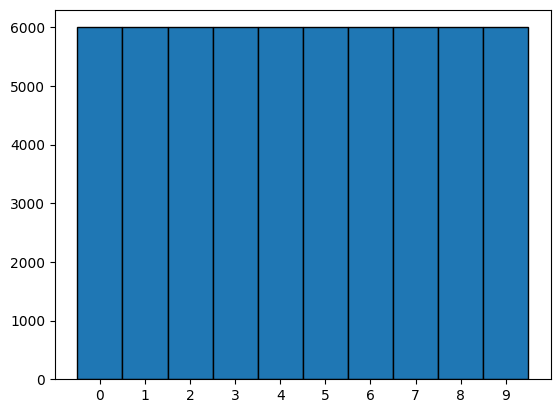

In [12]:
# Histogram showing the frequency of each class in the dataset
plt.hist(all_labels, bins=np.arange(11) - 0.5, edgecolor='black')
plt.xticks(range(10))
plt.show()

We can see that we have mixed distribution of frequencies among the 10 classes of handwritten digits with handwritten 1s having the most samples and the 5s having the least samples.


**_Q2: What happens if our distribution is very unbalanced meaning we have widely different quantities of the classes?_**

**Answer:** The model sees the common classes far more often, so it learns them well and predicts them too often, while rare classes get poor decision boundaries. Plain accuracy becomes misleading, because a model that always predicts the majority class still looks accurate. Fixes include class weights in the loss, over-sampling rare classes, under-sampling common ones, and metrics such as per-class recall or balanced accuracy. CIFAR-10 is balanced (6,000 images per class), so this does not affect our results.


Now, if we look at the distribution over the train, validation, and test sets, we can see that the distributions are roughly proportional to what we saw previously when the all of the data was contained within a single large dataset.


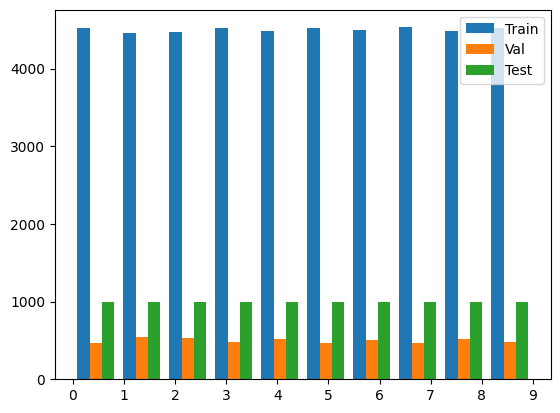

In [13]:
# Frequencies of each class in the 3 separate datasets
labels = np.unique(train_labels)
plt.hist([train_labels, val_labels, test_labels])
plt.xticks(labels)
plt.legend(['Train', 'Val', 'Test'])

Now we can get an idea of what our data actually looks like. Here, we have printed a single sample of each class and displayed their corresponding label above them.


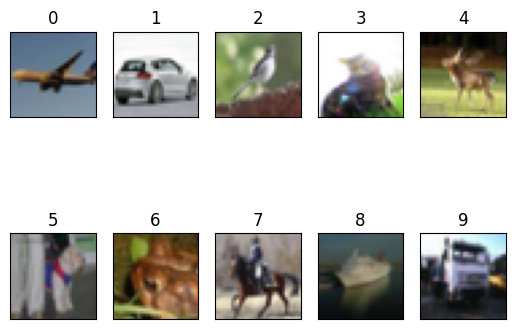

In [14]:
# Displaying one sample of each class
visualization_samples = []
plt.subplot(2, 5, 1)
for i in range(10):
    indices = np.where(train_labels == i)[0]
    rand_idx = indices[np.random.randint(0, len(indices) - 1)]
    plt.subplot(2, 5, i+1)
    plt.imshow(np.squeeze(train_images[rand_idx]))
    plt.yticks([])
    plt.xticks([])
    plt.title(i)

## Create the Dataloaders


In many cases our entire dataset may not fit entirely in memory (i.e. RAM). In our case of MNIST, this typically isn't a problem, but for larger datasets and higher dimensional data (i.e. ImageNet datasets), it is common that we need a way to load our data such that it fits in memory.

We can customize the code in the MNIST_Dataset class to allow use to only read data from the disk (Hard Drive or Solid State Drive) when needed. This can be seen in the PyTorch examples of the Dataset and Dataloader documentation/tutorials: https://pytorch.org/tutorials/beginner/basics/data_tutorial.html#creating-a-custom-dataset-for-your-files

In this case, we are not concerned with memory limitations, unless the system you are running this tutorial on is extremely limited in memory. Thus we have the entire dataset loaded into memory and can freely manipulate it.

In many cases, it is much more efficient to use data batching to batch our data when training to speed up training. Instead of inputting a single image, computing the loss, and then backpropogating the error and adjusting the weights, we can perform the forward pass (i.e. input) several images at once and then compute the loss on those samples together and then backpropogate their error.


**_Q3: What do we mean by "train faster" or "more efficiently" here? That is what is faster or more efficient?_**

**Answer:** "Faster" means the training run finishes in less wall-clock time: with batching the GPU processes many images at once as large matrix operations, and there are fewer optimizer steps and less Python overhead per epoch (1313 steps instead of 42,000 for batch size 32). "More efficient" means better use of the hardware and a smoother gradient, because the average over a batch is less noisy than the gradient from one image.


### Parameters


In [15]:
# In this tutorial, we will use a batch size of 32 whilst training
BATCH_SIZE = 32

In [16]:
# Here we initialize the Dataloaders, set the batch size to load BATCH_SIZE
# samples at a time and also perform a random shuffle of the samples within
# each set of data.
train_dataloader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)
val_dataloader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)
test_dataloader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

## Create the CNN Model


Here we instantiate two CNN models both being based off of Yann LeCun et. al.'s LeNet-5 CNN proposed in their publication "Gradient-Based Learning Applied to Document Recognition" circa 1998.


### Parameters


In [17]:
# We have 10 different classes of data we want to differentiate between
# (i.e. the handwritten single digit number zero thru nine)
NUM_CLASSES = 10

### Classic LeNet-5


Here we define a close-to-classical version of LeNet-5 which is very similar to what Yann LeCun et. al. proposed in 1998.


In [18]:
class OGLeNet5(torch.nn.Module):
    def __init__(self):
        super().__init__()
        # Define the layers
        self.conv1 = torch.nn.Conv2d(
            in_channels=3,
            out_channels=6,
            kernel_size=5,
            stride=1,
            padding=0
        )
        self.avgpool1 = torch.nn.AvgPool2d(kernel_size=2, stride=2)
        self.conv2 = torch.nn.Conv2d(
            in_channels=6,
            out_channels=16,
            kernel_size=5,
            stride=1,
            padding=0
        )
        self.avgpool2 = torch.nn.AvgPool2d(kernel_size=2, stride=2)
        self.flatten = torch.nn.Flatten()
        self.linear1 = torch.nn.Linear(400, 120)
        self.linear2 = torch.nn.Linear(120, 84)
        self.linear3 = torch.nn.Linear(84, out_features=NUM_CLASSES)

    def forward(self, x):
        x = self.conv1(x)
        x = torch.functional.F.tanh(x)
        x = self.avgpool1(x)
        x = self.conv2(x)
        x = torch.functional.F.tanh(x)
        x = self.avgpool2(x)
        x = self.flatten(x)
        x = self.linear1(x)
        x = torch.functional.F.tanh(x)
        x = self.linear2(x)
        x = torch.functional.F.tanh(x)
        x = self.linear3(x)
        return x

### Inspect the Original LeNet-5 Model


In [19]:
original_lenet5 = OGLeNet5()
summary(original_lenet5, (3, 32, 32), device='cpu')

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1            [-1, 6, 28, 28]             456
         AvgPool2d-2            [-1, 6, 14, 14]               0
            Conv2d-3           [-1, 16, 10, 10]           2,416
         AvgPool2d-4             [-1, 16, 5, 5]               0
           Flatten-5                  [-1, 400]               0
            Linear-6                  [-1, 120]          48,120
            Linear-7                   [-1, 84]          10,164
            Linear-8                   [-1, 10]             850
Total params: 62,006
Trainable params: 62,006
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 0.06
Params size (MB): 0.24
Estimated Total Size (MB): 0.31
----------------------------------------------------------------


### Define a More Modern LeNet-5


Here we provide a more modernize version of LeNet-5 with layers and operations that were not yet available or discovered at the time of LeNet-5's creation.


In [20]:
class ModernLeNet5(torch.nn.Module):
    def __init__(self):
        super().__init__()
        # Define the layers
        self.conv1 = torch.nn.Conv2d(
            in_channels=3,
            out_channels=6,
            kernel_size=5,
            stride=1,
            padding=0
        )
        self.batchnorm1 = torch.nn.BatchNorm2d(6)
        self.maxpool1 = torch.nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = torch.nn.Conv2d(
            in_channels=6,
            out_channels=16,
            kernel_size=5,
            stride=1,
            padding=0
        )
        self.batchnorm2 = torch.nn.BatchNorm2d(16)
        self.maxpool2 = torch.nn.MaxPool2d(kernel_size=2, stride=2)
        self.flatten = torch.nn.Flatten()
        self.linear1 = torch.nn.Linear(400, 120)
        self.linear2 = torch.nn.Linear(120, 84)
        self.linear3 = torch.nn.Linear(84, out_features=NUM_CLASSES)

    def forward(self, x):
        x = self.conv1(x)
        x = self.batchnorm1(x)
        x = torch.functional.F.relu(x)
        x = self.maxpool1(x)
        x = self.conv2(x)
        x = self.batchnorm2(x)
        x = torch.functional.F.relu(x)
        x = self.maxpool2(x)
        x = self.flatten(x)
        x = self.linear1(x)
        x = torch.functional.F.relu(x)
        x = self.linear2(x)
        x = torch.functional.F.relu(x)
        x = self.linear3(x)
        return x

### Inspect the Modernized LeNet-5 Model


In [21]:
modern_lenet5 = ModernLeNet5()
summary(modern_lenet5, (3, 32, 32), device='cpu')

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1            [-1, 6, 28, 28]             456
       BatchNorm2d-2            [-1, 6, 28, 28]              12
         MaxPool2d-3            [-1, 6, 14, 14]               0
            Conv2d-4           [-1, 16, 10, 10]           2,416
       BatchNorm2d-5           [-1, 16, 10, 10]              32
         MaxPool2d-6             [-1, 16, 5, 5]               0
           Flatten-7                  [-1, 400]               0
            Linear-8                  [-1, 120]          48,120
            Linear-9                   [-1, 84]          10,164
           Linear-10                   [-1, 10]             850
Total params: 62,050
Trainable params: 62,050
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 0.11
Params size (MB): 0.24
Estimated Tot

**_Q4: What are the architectural differences between these two models?_**

**Answer:** The layer sizes are the same, but the modern LeNet-5 changes three things. (1) It uses ReLU instead of tanh, which avoids saturating gradients and trains faster. (2) It uses max pooling instead of average pooling, which keeps the strongest response in each window. (3) It adds batch normalization after each convolution, which stabilizes training. This adds 44 parameters (62,050 vs. 62,006).


## Setup the Loss Functions and Optimizer


### Paremeters


In [22]:
# This is our learning rate for both models
LEARNING_RATE = 0.001

In [23]:
# Setup our loss function
loss = torch.nn.CrossEntropyLoss()

# Setup an optimizer for each of the two models
optim_original_lenet5 = torch.optim.Adam(
    original_lenet5.parameters(), lr=LEARNING_RATE)
optim_modern_lenet5 = torch.optim.Adam(
    modern_lenet5.parameters(), lr=LEARNING_RATE)

## Train the CNN Model


### Parameters


In [24]:
# Define the number of training epochs to loop of the entire dataset
NUM_EPOCHS = 10
# Determine if we should use
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [25]:
# Which device / GPU is this run using? (put this in the report's Hardware line)
print('DEVICE:', DEVICE)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('GPU: none (running on CPU)')

DEVICE: cuda
GPU: Tesla T4


In [26]:
def compute_accuracy(outputs, labels):
    """Use the outputs from the network and the expected labels to compute the
    accuracy of the network. 

    :param outputs: The output provided by running the model on input.
    :param labels: The ground-truth labels of the dataset.
    :return: The accuracy of the network based on the output of the network.
    :rtype: float
    """
    # Get the class index with the highest activation
    # In this case it corresponds to the digit with the highest likelihood of
    # being the number depicted in the input
    predictions = torch.argmax(outputs, 1)
    # Number of total predictions (i.e. the batch size)
    num_predictions = len(predictions)
    # Count the number of elements in the difference that are NOT zero
    # This indicates a mis-classification by the model
    num_incorrect = torch.count_nonzero(predictions - labels)
    # Compute the accuracy i.e. total - incorrect divided by total
    accuracy = (num_predictions - num_incorrect)/num_predictions
    return accuracy.item()

In [27]:
def train(
    train_dataloader: torch.utils.data.DataLoader,
    model: torch.nn.Module,
    loss_function,
    optimizer,
    epoch: int,
    num_epochs: int,
    total_steps: int,
    device: str,
    scheduler=None
) -> tuple:
    """Perform a full iteration over the entire training dataset.

    :param train_dataloader: The dataloader to use to get the data.
    :type train_dataloader: torch.utils.data.DataLoader
    :param model: The model to train.
    :type model: torch.nn.Module
    :param loss_function: The loss function to use to compute the loss.
    :param optimizer: The optimizer to use during training.
    :param epoch: The epoch number.
    :type epoch: int
    :param num_epochs: Total number of epochs.
    :type num_epochs: int
    :param total_steps: Total number of loops due to batching.
    :type total_steps: int
    :param device: The device to train on.
    :type device: str
    :return: A tuple containing average loss and accuracy.
    :rtype: tuple
    """
    running_acc = 0.0
    running_loss = 0.0
    for i, (images, labels) in enumerate(train_dataloader):
        # Move the data to the desired training device
        images = images.to(device)
        labels = labels.to(device)

        # Perform the forward pass
        outputs = model(images)

        # Compute the loss
        loss = loss_function(outputs, labels)

        # Compute accuracy metric
        acc = compute_accuracy(outputs, labels)

        # Zero the gradients
        optimizer.zero_grad()

        # Perform the backwards pass (i.e. backpropogate the error)
        loss.backward()

        # Optimize
        optimizer.step()

        # Step the learning-rate scheduler (only if one was given)
        if scheduler is not None:
            scheduler.step()

        # Add the running accuracy and loss
        running_loss += loss.item()
        running_acc += acc

        # Progressively print loss
        if (i+1) % 256 == 0:
            print(
                f'TRAINING --> Epoch: {epoch+1}/{num_epochs}, ' +
                f'Step: {i+1}/{total_steps}, ' +
                f'Loss: {running_loss / (i+1)}, '
                f'Accuracy: {running_acc / (i+1)}'
            )
    # Compute the average loss and accuracy for this epoch
    running_loss = running_loss / total_steps
    running_acc = running_acc / total_steps

    return running_loss, running_acc

In [28]:
def validation(
    val_dataloader: torch.utils.data.DataLoader,
    model: torch.nn.Module,
    loss_function,
    epoch: int,
    num_epochs: int,
    total_steps: int,
    device: str
) -> tuple:
    """Perform inference over the entire validation dataset without training
    the model.

    :param val_dataloader: The validation dataset DataLoader to get data.
    :type val_dataloader: torch.utils.data.DataLoader
    :param model: The model to use to perform inference.
    :type model: torch.nn.Module
    :param loss_function: The loss function to use to compute the loss with.
    :param epoch: The current epoch number.
    :type epoch: int
    :param num_epochs: Total number of epochs.
    :type num_epochs: int
    :param total_steps: Total number of loop iteration due to batching.
    :type total_steps: int
    :param device: The device to perform inference on.
    :type device: str
    :return: The average validation loss and accuracy.
    :rtype: tuple
    """
    running_loss = 0.0
    running_acc = 0.0
    # Now we run over the validation dataset without training
    if val_dataloader:
        # Disable the gradient calculations and updates
        with torch.no_grad():
            for i, (images, labels) in enumerate(val_dataloader):
                # Transfer input data to device
                images = images.to(device)
                labels = labels.to(device)

                # Perform inference
                outputs = model(images)

                # Compute validation loss
                loss = loss_function(outputs, labels)

                # Compute validation accuracy
                acc = compute_accuracy(outputs, labels)

                # Add the running accuracy and loss
                running_loss += loss.item()
                running_acc += acc

                # Progressively print loss
                if (i+1) % 256 == 0:
                    print(
                        f'VALIDATION --> Epoch: {epoch+1}/{num_epochs}, ' +
                        f'Step: {i+1}/{total_steps}, ' +
                        f'Val Loss: {running_loss / (i+1)}, ' +
                        f'Val Acc: {running_acc / (i+1)}'
                    )
    # Compute the average loss and accuracy for this epoch
    running_loss = running_loss / total_steps
    running_acc = running_acc / total_steps

    return running_loss, running_acc

In [29]:
def save_best_model(
    model: torch.nn.Module,
    model_save_path: Path,
    val_loss: float,
    val_losses: list,
    epoch: int,
    keep_models: bool = False
):
    """Save the model if it is the first epoch. Subsequently, save the model
    only if a lower validation loss is achieved whilst training.

    :param model: The model to save.
    :type model: torch.nn.Module
    :param model_save_path: The location to save the model to.
    :type model_save_path: Path
    :param val_loss: The current epoch's validation loss.
    :type val_loss: float
    :param val_losses: The history of all other validation losses.
    :type val_losses: list
    :param epoch: The current epoch number.
    :type epoch: int
    :param keep_models: Should all models be saved, defaults to False
    :type keep_models: bool, optional
    """
    # Should we keep all models or just one
    if keep_models:
        model_save_path = model_save_path / f'model_{epoch+1}_{val_loss}.pt'
    else:
        model_save_path = model_save_path / f'model_state_dict.pt'
    # Save the first model
    if len(val_losses) == 0:
        torch.save(
            model.state_dict(),
            model_save_path
        )
        print(
            'SAVING --> First epoch: \n' +
            f'Val Loss: {val_loss}\n' +
            f'Saving new model to:\n{model_save_path}'
        )
    elif val_loss < min(val_losses):
        # If our new validation loss is less than the previous best save the
        # model
        print(
            'SAVING --> Found model with better validation loss: \n' +
            f'New Best Val Loss: {val_loss}\n' +
            f'Old Best Val Loss: {min(val_losses)}\n'
            f'Saving new model to:\n{model_save_path}'
        )
        torch.save(
            model.state_dict(),
            model_save_path
        )

In [30]:
def train_model(
    train_dataloader: torch.utils.data.DataLoader,
    model: torch.nn.Module,
    loss_function: torch.nn.CrossEntropyLoss,
    optimizer: torch.optim.Adam,
    num_epochs: int,
    device: str,
    model_save_path: Path = Path('./models'),
    val_dataloader: torch.utils.data.DataLoader = None,
    scheduler=None,
) -> tuple:
    """Training loop which iterates over every image in the training dataset,
    performs the forward pass, computes the loss, and then performs the
    backwards pass. This also loops over the validation dataset and computes
    the validation loss and accuracy to determine the best model.

    See: https://pytorch.org/tutorials/beginner/introyt/trainingyt.html

    :param train_dataloader: The training dataset DataLoader to get data.
    :type train_dataloader: torch.utils.data.DataLoader
    :param model: The model to train.
    :type model: torch.nn.Module
    :param loss_function: The loss function to use to compute the loss.
    :type loss_function: torch.nn.CrossEntropyLoss
    :param optimizer: The optimizer to use in updating the weights.
    :type optimizer: torch.optim.Adam
    :param num_epochs: Total number of epoch to train for.
    :type num_epochs: int
    :param device: The device to perform training and validation on.
    :type device: str
    :param model_save_path: Save the model to, defaults to Path('./models')
    :type model_save_path: Path, optional
    :param val_dataloader: The validation dataset loader, defaults to None
    :type val_dataloader: torch.utils.data.DataLoader, optional
    :return: A tuple of shape (2, 2) that contains the history of the train
        and validation losses and accuracies.
    :rtype: tuple
    """
    print(f'Models will be saved to: {model_save_path}')
    # Lists for recording stats over epochs
    train_losses = []
    train_accs = []
    val_losses = []
    val_accs = []

    # Create the save path for the model
    if not model_save_path.exists():
        model_save_path.mkdir(exist_ok=True, parents=True)

    # Total number batches in training set
    train_total_steps = len(train_dataloader)
    val_total_steps = len(val_dataloader)

    # Perform training loop
    for epoch in range(num_epochs):
        # Enable model training
        model.train(True)

        # Enter the training function loop
        train_loss, train_acc = train(
            train_dataloader,
            model,
            loss_function,
            optimizer,
            epoch,
            num_epochs,
            train_total_steps,
            device,
            scheduler
        )
        print(
            f'TRAINING --> Epoch {epoch+1}/{num_epochs} DONE, ' +
            f'Avg Loss: {train_loss}, Avg Accuracy: {train_acc}'
        )

        # Switch to evaluation mode (BatchNorm uses running stats, no updates)
        model.eval()

        # Enter the validation loop
        val_loss, val_acc = validation(
            val_dataloader,
            model,
            loss_function,
            epoch,
            num_epochs,
            val_total_steps,
            device
        )
        print(
            f'VALIDATION --> Epoch {epoch+1}/{num_epochs} DONE, ' +
            f'Avg Loss: {val_loss}, Avg Accuracy: {val_acc}'
        )

        # Determine if we should save the model
        save_best_model(model, model_save_path, val_loss, val_losses, epoch)

        # Record the stats
        train_losses.append(train_loss)
        train_accs.append(train_acc)
        val_losses.append(val_loss)
        val_accs.append(val_acc)

    return (train_losses, train_accs), (val_losses, val_accs)

**_Q5: What is the purpose of the loss function?_**

**_Q6: What is validation doing?_**

**_Q7: Why do we perform validation and not just use the training loss/accuracy?_**

**Answer Q5:** The loss function turns the gap between the model's predictions and the true labels into one number that training tries to minimize. Backpropagation computes how that number changes with each weight, and the optimizer uses this to update the weights. We use cross-entropy, which suits multi-class classification and penalizes confident wrong predictions.

**Answer Q6:** After each epoch the model runs over the validation set with gradients turned off and no weight updates. This measures the loss and accuracy on images it has not trained on, and the lowest validation loss decides which checkpoint is saved as the best model.

**Answer Q7:** Training metrics keep improving even when the model is only memorizing the training images. Validation shows whether the model generalizes, so we can spot overfitting and pick the best epoch without touching the test set, which stays an unbiased final check.


In [31]:
def plot_epoch_metrics(x, y, data_names, title_prefix, yaxis_label):
    """Plot metrics with the number of epochs on the x axis and the metric of
    interest on the y axis. Note that this function differs based on the input.

    :param x: The values to use on the x-axis.
    :type x: list
    :param y: A list of lists containing len(x) data points to plot. The inner
        lists are the different series to plot.
    :type y: list
    :param data_names: Names of the series to use in the legend.
    :type data_names: str
    :param title_prefix: A prefix to add before everything else in the title.
    :type title_prefix: str
    :param yaxis_label: The label for the y axis.
    :type yaxis_label: str
    """
    # Plot multiple series of data
    for i in y:
        plt.plot(x, i)
    # Set the title
    plt.title(title_prefix + ' ' + ' vs. '.join(data_names) + ' ' + yaxis_label)
    # Set the y axis label
    plt.ylabel(yaxis_label)
    # Enable the legend with the appropriate names
    plt.legend(data_names)

In [32]:
# Train the original version of LeNet5
original_lenet5.to(DEVICE)
(train_losses, train_accs), (val_losses, val_accs) = train_model(
    train_dataloader,
    original_lenet5,
    loss,
    optim_original_lenet5,
    NUM_EPOCHS,
    DEVICE,
    model_save_path=Path('./models/original_lenet5'),
    val_dataloader=val_dataloader
)
# Get the best validation loss and accuracy
print(
    f'Best Validation Loss: {min(val_losses)} ' +
    f'after epoch {np.argmin(val_losses) + 1}'
)
print(
    f'Best Validation Acc: {max(val_accs)} ' +
    f'after epoch {np.argmax(val_accs) + 1}'
)

Models will be saved to: models/original_lenet5
TRAINING --> Epoch: 1/10, Step: 256/1407, Loss: 1.9152246206067502, Accuracy: 0.3121337890625
TRAINING --> Epoch: 1/10, Step: 512/1407, Loss: 1.838872272754088, Accuracy: 0.3433837890625
TRAINING --> Epoch: 1/10, Step: 768/1407, Loss: 1.7865175837650895, Accuracy: 0.3627522786458333
TRAINING --> Epoch: 1/10, Step: 1024/1407, Loss: 1.7411313878837973, Accuracy: 0.3800048828125
TRAINING --> Epoch: 1/10, Step: 1280/1407, Loss: 1.7022747671231628, Accuracy: 0.3937744140625
TRAINING --> Epoch 1/10 DONE, Avg Loss: 1.687103547690689, Avg Accuracy: 0.40011993603411516
VALIDATION --> Epoch 1/10 DONE, Avg Loss: 1.5481208471735572, Avg Accuracy: 0.4492436305732484
SAVING --> First epoch: 
Val Loss: 1.5481208471735572
Saving new model to:
models/original_lenet5/model_state_dict.pt
TRAINING --> Epoch: 2/10, Step: 256/1407, Loss: 1.4929720284417272, Accuracy: 0.4637451171875
TRAINING --> Epoch: 2/10, Step: 512/1407, Loss: 1.4845126075670123, Accuracy: 

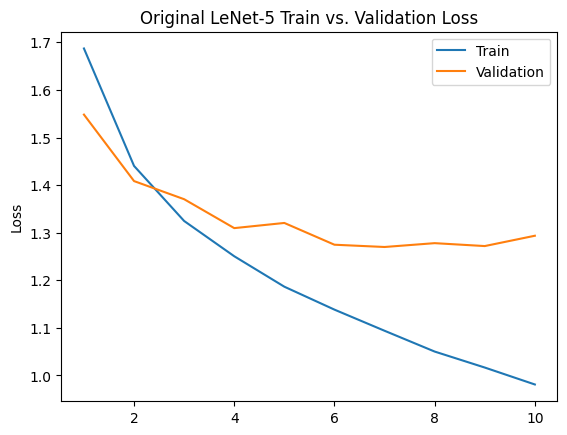

In [33]:
plot_epoch_metrics(
    np.arange(1, len(train_losses) + 1),
    [train_losses, val_losses],
    ['Train', 'Validation'],
    'Original LeNet-5',
    'Loss'
)

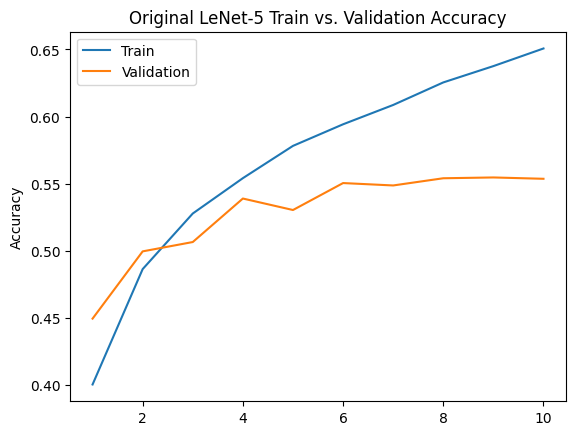

In [34]:
plot_epoch_metrics(
    np.arange(1, len(train_losses) + 1),
    [train_accs, val_accs],
    ['Train', 'Validation'],
    'Original LeNet-5',
    'Accuracy'
)

In [35]:
# Train the modern version of LeNet5
modern_lenet5.to(DEVICE)
(train_losses, train_accs), (val_losses, val_accs) = train_model(
    train_dataloader,
    modern_lenet5,
    loss,
    optim_modern_lenet5,
    NUM_EPOCHS,
    DEVICE,
    model_save_path=Path('./models/modern_lenet5'),
    val_dataloader=val_dataloader
)
# Get the best validation loss and accuracy
print(
    f'Best Validation Loss: {min(val_losses)} ' +
    f'after epoch {np.argmin(val_losses) + 1}'
)
print(
    f'Best Validation Acc: {max(val_accs)} ' +
    f'after epoch {np.argmax(val_accs) + 1}'
)

Models will be saved to: models/modern_lenet5
TRAINING --> Epoch: 1/10, Step: 256/1407, Loss: 1.8052698411047459, Accuracy: 0.32861328125
TRAINING --> Epoch: 1/10, Step: 512/1407, Loss: 1.6871721752686426, Accuracy: 0.37872314453125
TRAINING --> Epoch: 1/10, Step: 768/1407, Loss: 1.6140362406925608, Accuracy: 0.4085693359375
TRAINING --> Epoch: 1/10, Step: 1024/1407, Loss: 1.5613297385862097, Accuracy: 0.429229736328125
TRAINING --> Epoch: 1/10, Step: 1280/1407, Loss: 1.5159882655832917, Accuracy: 0.4480224609375
TRAINING --> Epoch 1/10 DONE, Avg Loss: 1.496425096202422, Avg Accuracy: 0.4556458777540867
VALIDATION --> Epoch 1/10 DONE, Avg Loss: 1.262369486556691, Avg Accuracy: 0.5400079617834395
SAVING --> First epoch: 
Val Loss: 1.262369486556691
Saving new model to:
models/modern_lenet5/model_state_dict.pt
TRAINING --> Epoch: 2/10, Step: 256/1407, Loss: 1.2605735007673502, Accuracy: 0.5472412109375
TRAINING --> Epoch: 2/10, Step: 512/1407, Loss: 1.2520042426185682, Accuracy: 0.552673

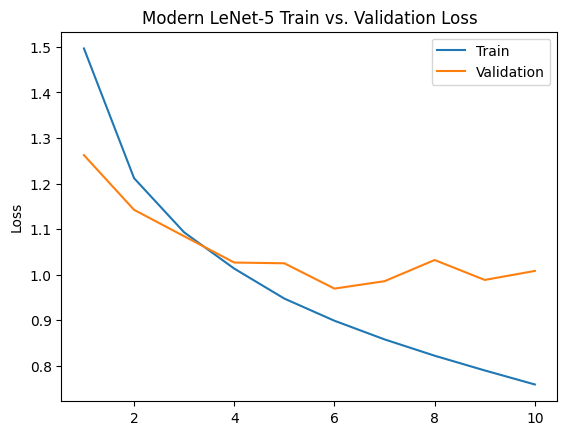

In [36]:
plot_epoch_metrics(
    np.arange(1, len(train_losses) + 1),
    [train_losses, val_losses],
    ['Train', 'Validation'],
    'Modern LeNet-5',
    'Loss'
)

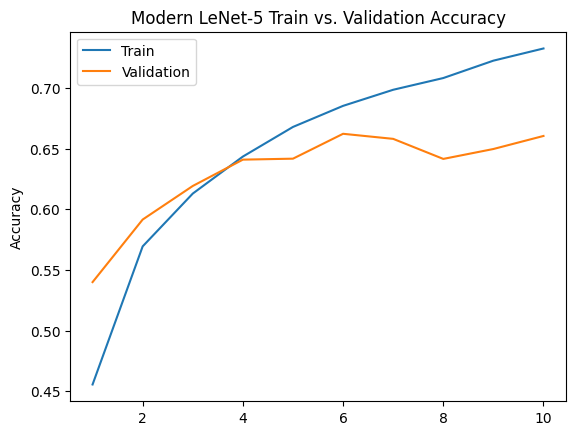

In [37]:
plot_epoch_metrics(
    np.arange(1, len(train_losses) + 1),
    [train_accs, val_accs],
    ['Train', 'Validation'],
    'Modern LeNet-5',
    'Accuracy'
)

**_Q8: Do you think training the models for additional epochs will help in any way? Explain your answer!_**

**Answer:** Not much. The original model's validation loss is lowest at epoch 7 (1.260) and higher at epoch 10 (1.301) while training loss keeps falling. The modern model's best validation loss is at epoch 9 (1.019), and the gap between training accuracy (71.4%) and validation accuracy (64.8%) is widening. Extra epochs would mostly add overfitting. Bigger gains come from augmentation, a learning-rate schedule or a larger model, as the VGG-style model below shows.


## Test the Model


Now that we have trained our model and chosen the best model based on the validation loss, let's test our saved models and compare them in terms of their loss and accuracy on the test dataset. If the models have been trained well, we should see they perform decently well.


In [38]:
def plot_confusion_matrix(labels, predictions):
    """This function generates a confusion matrix which shows how the model
    performs over the different classes in the dataset. In other words, this
    shows which classes the model 'confuses' with one another.

    :param labels: The ground-truth labels.
    :type labels: list
    :param predictions: The predictions provided by the model.
    :type predictions: list
    """
    # Create the confusion matrix
    cm = confusion_matrix(labels, predictions)
    # Create a matplotlib display for the confusion matrix
    cm_display = ConfusionMatrixDisplay(cm, display_labels=np.arange(10))
    # Plot the data
    cm_display.plot()
    # SHow the figure
    plt.show()

In [39]:
@torch.no_grad()
def test_model(
    test_dataloader: torch.utils.data.DataLoader,
    model_class: torch.nn.Module,
    model_weights_path: Path,
    device: str,
    loss_function
):
    """Load the saved model and evaluate it using the test dataset to determine
    how well it was trained.

    :param test_dataloader: The test dataset DataLoader to get the data from.
    :type test_dataloader: torch.utils.data.DataLoader
    :param model_class: The model to evaluate.
    :type model_class: torch.nn.Module
    :param model_weights_path: The path the the model's weights.
    :type model_weights_path: Path
    :param device: The device to use for evaluation (i.e. inference).
    :type device: str
    :param loss_function: The loss function to use to compute the test loss.
    :return: A tuple containing the total average loss and accuracy as well as
        two list containing the predictions and ground-truth labels.
    :rtype: tuple
    """
    # Initialize the model architecture
    model: torch.nn.Module = model_class()
    # Load the weights
    model.load_state_dict(torch.load(model_weights_path, weights_only=True))
    # Enter the model into evaluation mode (i.e. DO NOT TRAIN)
    model.eval()

    # Send the model to the device to use for inference
    model.to(device)
    # Number of batched iterations
    total_steps = len(test_dataloader)
    # Vars for metrics and results
    running_loss = 0.0
    running_acc = 0.0
    all_predictions = []
    all_labels = []
    # Testing/Evaluation loop
    for i, (images, labels) in enumerate(test_dataloader):
        # Send data to the inference device
        images = images.to(device)
        labels = labels.to(device)

        # Perform inference on batched data
        outputs = model(images)

        # Compute the loss (error) between the output and the ground-truths
        loss = loss_function(outputs, labels)

        # Compute the accuracy
        accuracy = compute_accuracy(outputs, labels)

        # Keep a running loss and accuracy for computing the average
        running_loss += loss.item()
        running_acc += accuracy

        # Concatenate all of the predictions and ground-truths
        all_predictions = all_predictions + torch.argmax(outputs, 1).tolist()
        all_labels = all_labels + labels.tolist()
    # Compute the average loss and accuracy
    running_loss = running_loss / total_steps
    running_acc = running_acc / total_steps

    return running_loss, running_acc, all_predictions, all_labels

In [40]:
og_test_loss, og_test_acc, predictions, labels = test_model(
    test_dataloader,
    OGLeNet5,
    './models/original_lenet5/model_state_dict.pt',
    DEVICE,
    loss
)
print('Original LeNet-5 Inference Performance')
print(f'Test dataset contains {len(test_dataset)} samples.')
print(f'Testing Avg Loss: {og_test_loss}')
print(f'Testing Avg Acc: {og_test_acc}')

Original LeNet-5 Inference Performance
Test dataset contains 10000 samples.
Testing Avg Loss: 1.2699176983330578
Testing Avg Acc: 0.5568091054313099


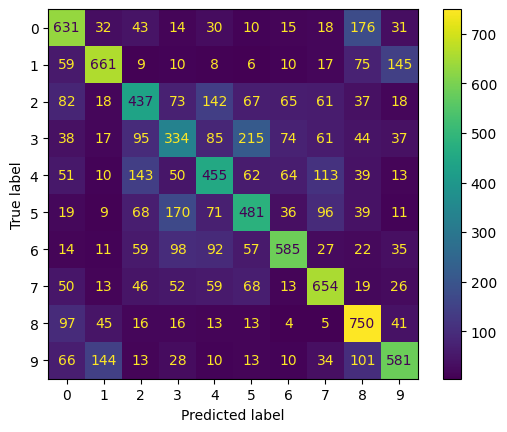

In [41]:
plot_confusion_matrix(labels, predictions)

In [42]:
modern_test_loss, modern_test_acc, predictions, labels = test_model(
    test_dataloader,
    ModernLeNet5,
    './models/modern_lenet5/model_state_dict.pt',
    DEVICE,
    loss
)
print('Modern LeNet-5 Inference Performance')
print(f'Test dataset contains {len(test_dataset)} samples.')
print(f'Testing Avg Loss: {modern_test_loss}')
print(f'Testing Avg Acc: {modern_test_acc}')

Modern LeNet-5 Inference Performance
Test dataset contains 10000 samples.
Testing Avg Loss: 0.984697601665704
Testing Avg Acc: 0.6576477635782748


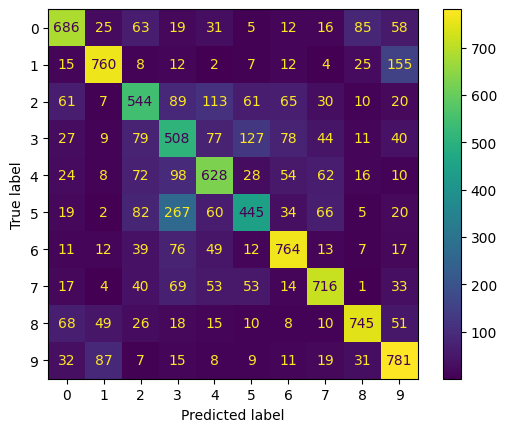

In [43]:
plot_confusion_matrix(labels, predictions)

**_Q9: How does the test loss and accuracy compare to the best training and validation metrics?_**

**Answer:** Test results are close to the best validation results and below the training results. Original: test accuracy 55.68% (loss 1.270) vs. best validation 55.45% (loss 1.270) and final training accuracy 65.1%. Modern: test accuracy 65.76% (loss 0.985) vs. best validation 66.22% (loss 0.969) and final training accuracy 73.3%. The close match means the validation set predicted test performance well, and the gap to training accuracy shows the amount of overfitting.


**_Q10: How do you think we could compute the latency inside the `test_model` function? In other words, what code do we add to `test_model` to measure the time it takes to give the model input and then get the output?_**

**Answer:** We can wrap the forward pass with timing code. Because CUDA runs asynchronously, call `torch.cuda.synchronize()` before and after the forward pass and read `time.perf_counter()` at both points; the difference times 1000 is the latency in milliseconds. Averaging over many images after a warm-up gives a stable per-image latency.


## Extension: VGG-style CNN on CIFAR-10
Everything above (the LeNet-5 results) is the required baseline and is unchanged. From here on we add a **VGG-style CNN**, which is a deeper CNN made of stacks of 3x3 convolutions with batch normalization. It reuses the same data split, the same `train_model` / `test_model` functions and the same plotting functions as above. Run this part on a **GPU**.

### Data augmentation for the VGG training set
Random crop (4-pixel padding) and random horizontal flip are applied to the **training images only**. Validation and test use the same un-augmented dataloaders as before.

In [44]:
def transform_aug(image):
    """Random crop with 4 pixels of padding + random horizontal flip, then the
    same scaling/normalization as `transform`. Input is a 32x32x3 uint8 image."""
    x = np.pad(image, ((4, 4), (4, 4), (0, 0)), mode='constant')
    i, j = np.random.randint(0, 9, size=2)
    x = x[i:i + 32, j:j + 32, :]
    if np.random.rand() < 0.5:
        x = x[:, ::-1, :]
    return transform(np.ascontiguousarray(x))


train_dataset_aug = MNIST_Dataset(
    train_images, train_labels,
    transform=transform_aug, target_transform=target_transform)

VGG_BATCH_SIZE = 128
train_dataloader_aug = torch.utils.data.DataLoader(
    train_dataset_aug, batch_size=VGG_BATCH_SIZE, shuffle=True)
print(f'Augmented training set: {len(train_dataset_aug)} images, {len(train_dataloader_aug)} batches per epoch')

Augmented training set: 45000 images, 352 batches per epoch


### Create the VGG-style model
Four blocks of two 3x3 convolutions (each followed by batch norm and ReLU) and a 2x2 max pool. Channels double each block (64, 128, 256, 512), and the image size shrinks 32 -> 16 -> 8 -> 4 -> 2.

In [45]:
def vgg_block(in_ch, out_ch, convs=2):
    layers = []
    for _ in range(convs):
        layers += [
            torch.nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            torch.nn.BatchNorm2d(out_ch),
            torch.nn.ReLU(inplace=True)
        ]
        in_ch = out_ch
    layers.append(torch.nn.MaxPool2d(kernel_size=2, stride=2))
    return torch.nn.Sequential(*layers)


class VGGStyle(torch.nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        self.features = torch.nn.Sequential(
            vgg_block(3, 64),
            vgg_block(64, 128),
            vgg_block(128, 256),
            vgg_block(256, 512),
        )
        self.classifier = torch.nn.Sequential(
            torch.nn.Flatten(),
            torch.nn.Linear(512 * 2 * 2, 512),
            torch.nn.ReLU(inplace=True),
            torch.nn.Dropout(dropout),
            torch.nn.Linear(512, NUM_CLASSES)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

### Inspect the VGG-style model

In [46]:
vgg_model = VGGStyle()
summary(vgg_model, (3, 32, 32), device='cpu')

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]           1,728
       BatchNorm2d-2           [-1, 64, 32, 32]             128
              ReLU-3           [-1, 64, 32, 32]               0
            Conv2d-4           [-1, 64, 32, 32]          36,864
       BatchNorm2d-5           [-1, 64, 32, 32]             128
              ReLU-6           [-1, 64, 32, 32]               0
         MaxPool2d-7           [-1, 64, 16, 16]               0
            Conv2d-8          [-1, 128, 16, 16]          73,728
       BatchNorm2d-9          [-1, 128, 16, 16]             256
             ReLU-10          [-1, 128, 16, 16]               0
           Conv2d-11          [-1, 128, 16, 16]         147,456
      BatchNorm2d-12          [-1, 128, 16, 16]             256
             ReLU-13          [-1, 128, 16, 16]               0
        MaxPool2d-14            [-1, 12

### Optimizer and learning-rate schedule
SGD with momentum and a one-cycle learning-rate schedule (the rate ramps up, then decays), which is what lets this model reach high accuracy in about 30 epochs.

In [47]:
VGG_EPOCHS = 30
VGG_MAX_LR = 0.1

optim_vgg = torch.optim.SGD(
    vgg_model.parameters(), lr=VGG_MAX_LR, momentum=0.9,
    weight_decay=5e-4, nesterov=True)
scheduler_vgg = torch.optim.lr_scheduler.OneCycleLR(
    optim_vgg, max_lr=VGG_MAX_LR,
    epochs=VGG_EPOCHS, steps_per_epoch=len(train_dataloader_aug))

### Train the VGG-style model

In [48]:
# Train the VGG-style model
vgg_model.to(DEVICE)
(vgg_train_losses, vgg_train_accs), (vgg_val_losses, vgg_val_accs) = train_model(
    train_dataloader_aug,
    vgg_model,
    loss,
    optim_vgg,
    VGG_EPOCHS,
    DEVICE,
    model_save_path=Path('./models/vgg_style'),
    val_dataloader=val_dataloader,
    scheduler=scheduler_vgg
)
# Get the best validation loss and accuracy
print(
    f'Best Validation Loss: {min(vgg_val_losses)} ' +
    f'after epoch {np.argmin(vgg_val_losses) + 1}'
)
print(
    f'Best Validation Acc: {max(vgg_val_accs)} ' +
    f'after epoch {np.argmax(vgg_val_accs) + 1}'
)

Models will be saved to: models/vgg_style
TRAINING --> Epoch: 1/30, Step: 256/352, Loss: 1.4484257870353758, Accuracy: 0.4693603515625
TRAINING --> Epoch 1/30 DONE, Avg Loss: 1.3491056199100884, Avg Accuracy: 0.5076744002713398
VALIDATION --> Epoch 1/30 DONE, Avg Loss: 0.9875253564233233, Avg Accuracy: 0.6498805732484076
SAVING --> First epoch: 
Val Loss: 0.9875253564233233
Saving new model to:
models/vgg_style/model_state_dict.pt
TRAINING --> Epoch: 2/30, Step: 256/352, Loss: 0.9335284777916968, Accuracy: 0.6724853515625
TRAINING --> Epoch 2/30 DONE, Avg Loss: 0.912929951297966, Avg Accuracy: 0.6805308948863636
VALIDATION --> Epoch 2/30 DONE, Avg Loss: 1.0044876955876685, Avg Accuracy: 0.6632165605095541
TRAINING --> Epoch: 3/30, Step: 256/352, Loss: 0.8063680145423859, Accuracy: 0.727813720703125
TRAINING --> Epoch 3/30 DONE, Avg Loss: 0.8016816767101939, Avg Accuracy: 0.7310901988636364
VALIDATION --> Epoch 3/30 DONE, Avg Loss: 0.8336616689991799, Avg Accuracy: 0.7239251592356688
SA

### Final training and validation numbers (VGG-style)

In [49]:
print(f'Final Train Loss: {vgg_train_losses[-1]:.4f}')
print(f'Final Train Acc:  {vgg_train_accs[-1]*100:.2f}%')
print(f'Final Val Loss:   {vgg_val_losses[-1]:.4f}')
print(f'Final Val Acc:    {vgg_val_accs[-1]*100:.2f}%')

Final Train Loss: 0.0397
Final Train Acc:  98.75%
Final Val Loss:   0.2646
Final Val Acc:    92.24%


### Learning curves (VGG-style)

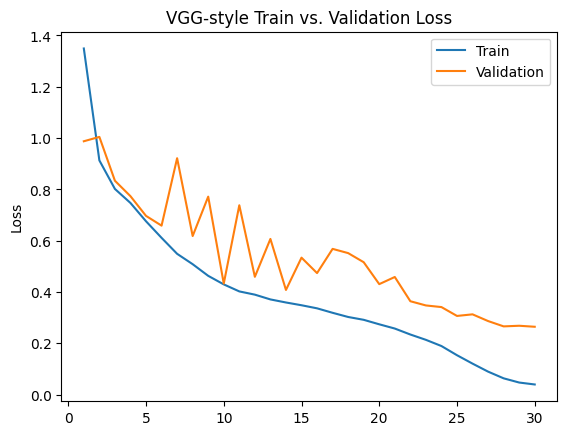

In [50]:
plot_epoch_metrics(
    np.arange(1, len(vgg_train_losses) + 1),
    [vgg_train_losses, vgg_val_losses],
    ['Train', 'Validation'],
    'VGG-style',
    'Loss'
)

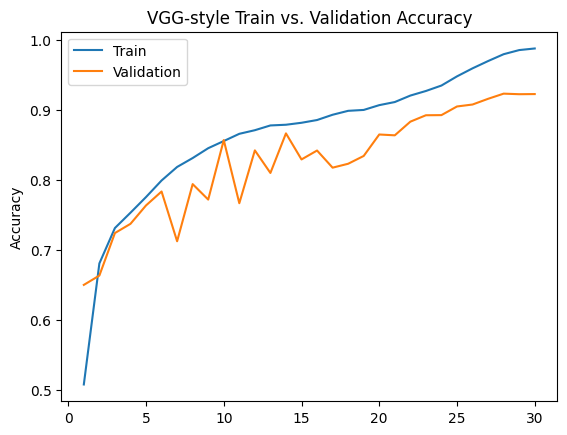

In [51]:
plot_epoch_metrics(
    np.arange(1, len(vgg_train_losses) + 1),
    [vgg_train_accs, vgg_val_accs],
    ['Train', 'Validation'],
    'VGG-style',
    'Accuracy'
)

### Test the VGG-style model

In [52]:
vgg_test_loss, vgg_test_acc, predictions, labels = test_model(
    test_dataloader,
    VGGStyle,
    './models/vgg_style/model_state_dict.pt',
    DEVICE,
    loss
)
print('VGG-style Inference Performance')
print(f'Test dataset contains {len(test_dataset)} samples.')
print(f'Testing Avg Loss: {vgg_test_loss}')
print(f'Testing Avg Acc: {vgg_test_acc}')

VGG-style Inference Performance
Test dataset contains 10000 samples.
Testing Avg Loss: 0.26627546622932624
Testing Avg Acc: 0.9240215654952076


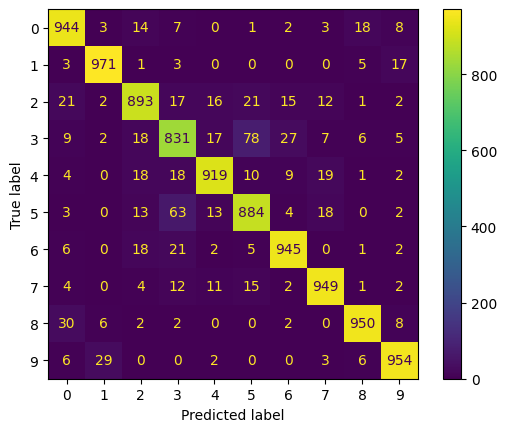

In [53]:
plot_confusion_matrix(labels, predictions)

### Summary: test accuracy of all three models

In [54]:
print(f'Original LeNet-5 test accuracy: {og_test_acc*100:.2f}%')
print(f'Modern LeNet-5 test accuracy:   {modern_test_acc*100:.2f}%')
print(f'VGG-style test accuracy:        {vgg_test_acc*100:.2f}%')

Original LeNet-5 test accuracy: 55.68%
Modern LeNet-5 test accuracy:   65.76%
VGG-style test accuracy:        92.40%


In [55]:
import time
from copy import deepcopy

model = VGGStyle()
model.load_state_dict(torch.load('./models/vgg_style/model_state_dict.pt', weights_only=True))
model.to(DEVICE).eval()

def cuda_sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

correct, lat_ms = 0, []
with torch.no_grad():
    for i in range(20):                      # warm-up runs
        model(test_dataset[i][0].unsqueeze(0).to(DEVICE))
    cuda_sync()
    for img, lab in test_dataset:            # one image at a time
        x = img.unsqueeze(0).to(DEVICE)
        cuda_sync(); t_in = time.perf_counter()
        out = model(x)
        cuda_sync(); t_out = time.perf_counter()
        lat_ms.append((t_out - t_in) * 1000)
        correct += int(out.argmax(1).item() == lab)

fp32_acc = correct / len(test_dataset)
fp32_lat = float(np.mean(lat_ms))
print('GPU:', torch.cuda.get_device_name(0))
print(f'Test images: {len(test_dataset)}')
print(f'Accuracy: {fp32_acc:.4f} | Latency: {fp32_lat:.3f} ms | Score: {fp32_acc/fp32_lat:.4f}')

GPU: Tesla T4
Test images: 10000
Accuracy: 0.9240 | Latency: 1.313 ms | Score: 0.7035


In [57]:
# ---------- Uniform symmetric per-tensor quant/dequant ----------
def _qparams_symmetric_per_tensor(t, bits):
    qmax = (1 << (bits - 1)) - 1
    max_abs = t.abs().max()
    scale = (max_abs / qmax) if max_abs > 0 else torch.tensor(1.0, device=t.device, dtype=t.dtype)
    return scale, qmax

def quantize_dequantize_tensor(t, bits):
    scale, qmax = _qparams_symmetric_per_tensor(t, bits)
    q = torch.clamp(torch.round(t / scale), min=-qmax-1, max=qmax)
    return (q * scale).to(t.dtype)

@torch.no_grad()
def quantize_model_weights(model, bits):
    qmodel = deepcopy(model)
    for n, m in qmodel.named_modules():
        if isinstance(m, (torch.nn.Conv2d, torch.nn.Linear)):
            m.weight.copy_(quantize_dequantize_tensor(m.weight, bits))
    return qmodel

class ActCalibrator(torch.nn.Module):
    def __init__(self, model, modules_to_calib=(torch.nn.Conv2d, torch.nn.Linear)):
        super().__init__()
        self.model = model
        self.handles = []
        self.act_max = {}
        def hook(name):
            def _fn(_m, _in, out):
                with torch.no_grad():
                    max_abs = out.detach().abs().max().item()
                    self.act_max[name] = max(self.act_max.get(name, 0.0), max_abs)
            return _fn
        for name, m in self.model.named_modules():
            if isinstance(m, modules_to_calib):
                self.handles.append(m.register_forward_hook(hook(name)))
    def forward(self, x):
        return self.model(x)
    def clear(self):
        for h in self.handles: h.remove()
        self.handles = []

class ActQuantWrapper(torch.nn.Module):
    def __init__(self, model, act_max_dict, act_bits=8, modules_to_quant=(torch.nn.Conv2d, torch.nn.Linear)):
        super().__init__()
        self.model = model
        self.act_max = act_max_dict
        self.act_bits = act_bits
        self.handles = []
        def make_hook(name):
            def _hook(_m, _in, out):
                max_abs = self.act_max.get(name, None)
                if max_abs is None or max_abs == 0:
                    return out
                qmax = (1 << (self.act_bits - 1)) - 1
                scale = max_abs / qmax
                q = torch.clamp(torch.round(out/scale), min=-qmax-1, max=qmax)
                return (q * scale).to(out.dtype)
            return _hook
        for name, m in self.model.named_modules():
            if isinstance(m, modules_to_quant):
                self.handles.append(m.register_forward_hook(make_hook(name)))
    def forward(self, x):
        return self.model(x)
    def clear(self):
        for h in self.handles: h.remove()
        self.handles = []

def evaluate_accuracy_latency(model, test_loader, device, warmup=10):
    model.eval()
    all_labels, all_preds, lat_ms = [], [], []
    with torch.no_grad():
        it = iter(test_loader)
        for _ in range(min(warmup, len(test_loader))):
            imgs, _ = next(it)
            _ = model(imgs[:1].to(device))
    with torch.no_grad():
        for images, labels in test_loader:
            for i in range(images.size(0)):
                img = images[i:i+1].to(device)
                cuda_sync(); start = time.perf_counter()
                out = model(img)
                cuda_sync(); end = time.perf_counter()
                lat_ms.append((end - start) * 1000.0)
                all_preds.append(out.argmax(1).item())
                all_labels.append(int(labels[i]))
    acc = (np.array(all_preds) == np.array(all_labels)).mean()
    return acc, float(np.mean(lat_ms))

def run_weight_only_ptq(model_fp, bits_list, test_loader, device):
    results = []
    for bits in bits_list:
        qmodel = quantize_model_weights(model_fp, bits).to(device)
        acc, lat = evaluate_accuracy_latency(qmodel, test_loader, device)
        results.append({'mode': f'W-only INT{bits}', 'accuracy': float(acc),
                        'avg_latency_ms': lat, 'score': float(acc / lat)})
        print(f"[W-only INT{bits}] acc={acc:.4f}, lat={lat:.3f} ms, score={acc/lat:.6f}")
    return results

@torch.no_grad()
def calibrate_activations(model_fp, calib_loader, device, num_batches=50):
    cal = ActCalibrator(deepcopy(model_fp).to(device))
    cal.eval()
    for n, (images, _) in enumerate(calib_loader):
        _ = cal(images.to(device))
        if n + 1 >= num_batches: break
    cal.clear()
    return cal.act_max

def run_weight_act_ptq(model_fp, bits_w, bits_a, calib_loader, test_loader, device, calib_batches=50):
    qmodel_w = quantize_model_weights(model_fp, bits_w).to(device)
    act_max = calibrate_activations(qmodel_w, calib_loader, device, num_batches=calib_batches)
    qwrap = ActQuantWrapper(qmodel_w, act_max, act_bits=bits_a).to(device)
    acc, lat = evaluate_accuracy_latency(qwrap, test_loader, device)
    print(f"[W{bits_w}/A{bits_a}] acc={acc:.4f}, lat={lat:.3f} ms, score={acc/lat:.6f}")
    qwrap.clear()
    return {'mode': f'W{bits_w}/A{bits_a}', 'accuracy': float(acc),
            'avg_latency_ms': lat, 'score': float(acc / lat)}

In [58]:
import pandas as pd

test_loader = test_dataloader     # your notebook's names
val_loader = val_dataloader

results = [{'mode': 'FP32 (baseline)', 'accuracy': fp32_acc,
            'avg_latency_ms': fp32_lat, 'score': fp32_acc / fp32_lat}]

results += run_weight_only_ptq(model, [32, 16, 8], test_loader, DEVICE)

for bw in [8, 16, 32]:
    for ba in [8, 16, 32]:
        results.append(run_weight_act_ptq(model, bw, ba, val_loader, test_loader, DEVICE))

results_df = pd.DataFrame(results)
display(results_df)

[W-only INT32] acc=0.9240, lat=1.255 ms, score=0.736213
[W-only INT16] acc=0.9240, lat=1.248 ms, score=0.740558
[W-only INT8] acc=0.9246, lat=1.245 ms, score=0.742471
[W8/A8] acc=0.9243, lat=2.074 ms, score=0.445590
[W8/A16] acc=0.9245, lat=2.058 ms, score=0.449253
[W8/A32] acc=0.9246, lat=2.076 ms, score=0.445355
[W16/A8] acc=0.9247, lat=2.031 ms, score=0.455329
[W16/A16] acc=0.9240, lat=2.024 ms, score=0.456477
[W16/A32] acc=0.9240, lat=2.068 ms, score=0.446765
[W32/A8] acc=0.9249, lat=2.043 ms, score=0.452706
[W32/A16] acc=0.9240, lat=2.047 ms, score=0.451304
[W32/A32] acc=0.9240, lat=2.065 ms, score=0.447370


,mode,accuracy,avg_latency_ms,score
0,FP32 (baseline),0.9240,1.313493,0.703468
1,W-only INT32,0.9240,1.255072,0.736213
2,W-only INT16,0.9240,1.247707,0.740558
3,W-only INT8,0.9246,1.245301,0.742471
4,W8/A8,0.9243,2.074329,0.445590
5,W8/A16,0.9245,2.057860,0.449253
6,W8/A32,0.9246,2.076095,0.445355
7,W16/A8,0.9247,2.030839,0.455329
8,W16/A16,0.9240,2.024199,0.456477
9,W16/A32,0.9240,2.068202,0.446765


In [59]:
# ---- Better rounding: one scale per filter (per-channel) ----
def quantize_per_channel(w, bits):
    qmax = (1 << (bits - 1)) - 1
    dims = tuple(range(1, w.dim()))                  # everything except the filter index
    max_abs = w.abs().amax(dim=dims, keepdim=True)   # biggest weight in EACH filter
    scale = torch.where(max_abs > 0, max_abs / qmax, torch.ones_like(max_abs))
    q = torch.clamp(torch.round(w / scale), -qmax - 1, qmax)
    return q * scale

@torch.no_grad()
def quantize_model_weights_per_channel(model, bits):
    qmodel = deepcopy(model)
    for m in qmodel.modules():
        if isinstance(m, (torch.nn.Conv2d, torch.nn.Linear)):
            m.weight.copy_(quantize_per_channel(m.weight, bits))
    return qmodel

# ---- Compare old rounding vs new rounding ----
@torch.no_grad()
def check(qmodel, name):
    qmodel.eval()
    correct, same, total, w_err = 0, 0, 0, 0.0
    for (n1, p1), (n2, p2) in zip(model.named_parameters(), qmodel.named_parameters()):
        if 'weight' in n1 and p1.dim() > 1:
            w_err += (p1 - p2).abs().mean().item()
    for images, labels in test_dataloader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        p_fp = model(images).argmax(1)
        p_q = qmodel(images).argmax(1)
        correct += (p_q == labels).sum().item()
        same += (p_q == p_fp).sum().item()
        total += labels.size(0)
    print(f'{name:22s} accuracy={correct/total:.4f} | same answer as FP32: '
          f'{100*same/total:.2f}% | avg weight error={w_err:.6f}')

for bits in [16, 8]:
    check(quantize_model_weights(model, bits).to(DEVICE),             f'INT{bits} per-layer (old)')
    check(quantize_model_weights_per_channel(model, bits).to(DEVICE), f'INT{bits} per-channel (new)')

INT16 per-layer (old)  accuracy=0.9240 | same answer as FP32: 100.00% | avg weight error=0.000017
INT16 per-channel (new) accuracy=0.9240 | same answer as FP32: 100.00% | avg weight error=0.000010
INT8 per-layer (old)   accuracy=0.9246 | same answer as FP32: 99.80% | avg weight error=0.004399
INT8 per-channel (new) accuracy=0.9241 | same answer as FP32: 99.86% | avg weight error=0.002456
